# Explainable Machine Learning for High-Revenue Hoya Marketplace Listings

### Data Loading and Cleaning

In [164]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

pd.set_option("display.max_columns", None)

In [165]:
df_ml = pd.read_csv(
    "../data/shopee_hoya_clean.csv"
)

print(df_ml.shape)

df_ml.head()

(419, 11)


,product_name,variety,price,number_sold,location,rating,number_of_reviews,marketplace,scraping_date,product_url,shop_name
0,Hoya Cumigiana,Cumingiana,10000,5,Kab. Lumajang,4.90,497,Shopee,2026-06-11,https://shopee.co.id/product/348755541/8915296529,Ngundang anggrek
1,Hoya Lacunosa Rimbun Bunganya Wangi,Lacunosa,12000,5,Kab. Lumajang,4.93,307,Shopee,2026-06-11,https://shopee.co.id/product/348755541/6579385658,Ngundang anggrek
2,Tanaman Hoya Carnosa Tricolor Atau Crimsom Pri...,Carnosa,34500,3,Kab. Bandung Barat,4.98,84,Shopee,2026-06-11,https://shopee.co.id/product/104126944/6352344959,Shofiflora
3,Sekulen Cluster Hoya Love Varigata Bercabang,Kerrii,27500,7,Kab. Bandung Barat,4.94,48,Shopee,2026-06-11,https://shopee.co.id/product/163019197/2871789...,Kaktus Store
4,Hoya kuning cerah,Unidentified,20000,3,Kab. Lumajang,4.88,97,Shopee,2026-06-11,https://shopee.co.id/product/348755541/8787796573,Ngundang anggrek


In [166]:
# exclude_varieties = [

#     "Unidentified"

#     # "Bunga",

#     # "Unknown",

#     # "Other"
# ]

# df_ml = (
#     df[
#         ~df["variety"].isin(
#             exclude_varieties
#         )
#     ]
#     .copy()
# )

# print(df_ml.shape)

In [167]:
df_ml["estimated_revenue"] = (
    df_ml["price"]
    *
    df_ml["number_sold"]
)

### Create Classification Target

In [168]:
median_revenue = (
    df_ml["estimated_revenue"]
    .median()
)

df_ml["high_revenue"] = (
    df_ml["estimated_revenue"]
    >
    median_revenue
).astype(int)

df_ml["high_revenue"].value_counts()

high_revenue
0    222
1    197
Name: count, dtype: int64

### Features

In [169]:
X = df_ml[
    [
        "price",
        "rating",
        "number_of_reviews",
        "variety",
        "location"
    ]
].copy()

X = pd.get_dummies(
    X,
    columns=[
        "variety",
        "location"
    ],
    drop_first=True
)

y = df_ml["high_revenue"]

print(X.shape)

(419, 153)


### Train / Test Split

In [170]:
X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=0.20,

    stratify=y,

    random_state=42
)

## Logistic Regression
### Train Logistic Regression

In [171]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logit = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000))
])

logit.fit(
    X_train,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](153,)","['price','rating','number_of_reviews',...,'location_Surakarta (Solo)', 'location_Tangerang','location_Tasikmalaya']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,153
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


### Logistic Predictions

In [172]:
y_pred_logit = logit.predict(
    X_test
)

In [173]:
logit_accuracy = accuracy_score(
    y_test,
    y_pred_logit
)

logit_precision = precision_score(
    y_test,
    y_pred_logit
)

logit_recall = recall_score(
    y_test,
    y_pred_logit
)

logit_f1 = f1_score(
    y_test,
    y_pred_logit
)

print("LOGISTIC REGRESSION")

print(
    f"Accuracy : {logit_accuracy:.4f}"
)

print(
    f"Precision: {logit_precision:.4f}"
)

print(
    f"Recall   : {logit_recall:.4f}"
)

print(
    f"F1 Score : {logit_f1:.4f}"
)

LOGISTIC REGRESSION
Accuracy : 0.6905
Precision: 0.6444
Recall   : 0.7436
F1 Score : 0.6905


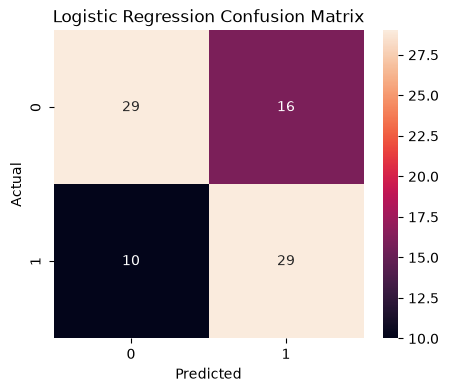

In [174]:
cm = confusion_matrix(
    y_test,
    y_pred_logit
)

plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d"
)

plt.title(
    "Logistic Regression Confusion Matrix"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

## Random Forest
### Train Random Forest

In [175]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(

    n_estimators=300,

    max_depth=8,

    random_state=42
)

rf.fit(
    X_train,
    y_train
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",8
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap:

### RF Predictions

In [176]:
y_pred_rf = rf.predict(
    X_test
)

In [177]:
rf_accuracy = accuracy_score(
    y_test,
    y_pred_rf
)

rf_precision = precision_score(
    y_test,
    y_pred_rf
)

rf_recall = recall_score(
    y_test,
    y_pred_rf
)

rf_f1 = f1_score(
    y_test,
    y_pred_rf
)

print("RANDOM FOREST")

print(
    f"Accuracy : {rf_accuracy:.4f}"
)

print(
    f"Precision: {rf_precision:.4f}"
)

print(
    f"Recall   : {rf_recall:.4f}"
)

print(
    f"F1 Score : {rf_f1:.4f}"
)

RANDOM FOREST
Accuracy : 0.7857
Precision: 0.8387
Recall   : 0.6667
F1 Score : 0.7429


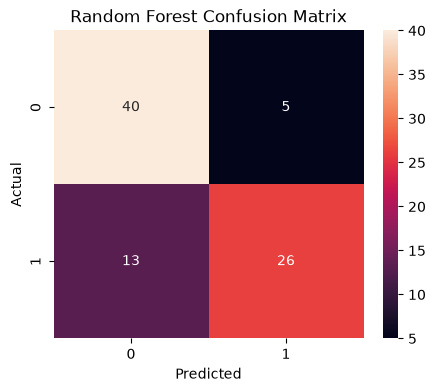

In [178]:
cm = confusion_matrix(
    y_test,
    y_pred_rf
)

plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d"
)

plt.title(
    "Random Forest Confusion Matrix"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

### ROC - AUC

In [179]:
from sklearn.metrics import roc_auc_score

rf_prob = rf.predict_proba(X_test)[:,1]

roc_auc = roc_auc_score(
    y_test,
    rf_prob
)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.8660968660968661


## Model Comparison

In [180]:
comparison = pd.DataFrame({

    "Model": [

        "Logistic Regression",

        "Random Forest"
    ],

    "Accuracy": [

        logit_accuracy,

        rf_accuracy
    ],

    "Precision": [

        logit_precision,

        rf_precision
    ],

    "Recall": [

        logit_recall,

        rf_recall
    ],

    "F1": [

        logit_f1,

        rf_f1
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.690476,0.644444,0.743590,0.690476
1,Random Forest,0.785714,0.838710,0.666667,0.742857


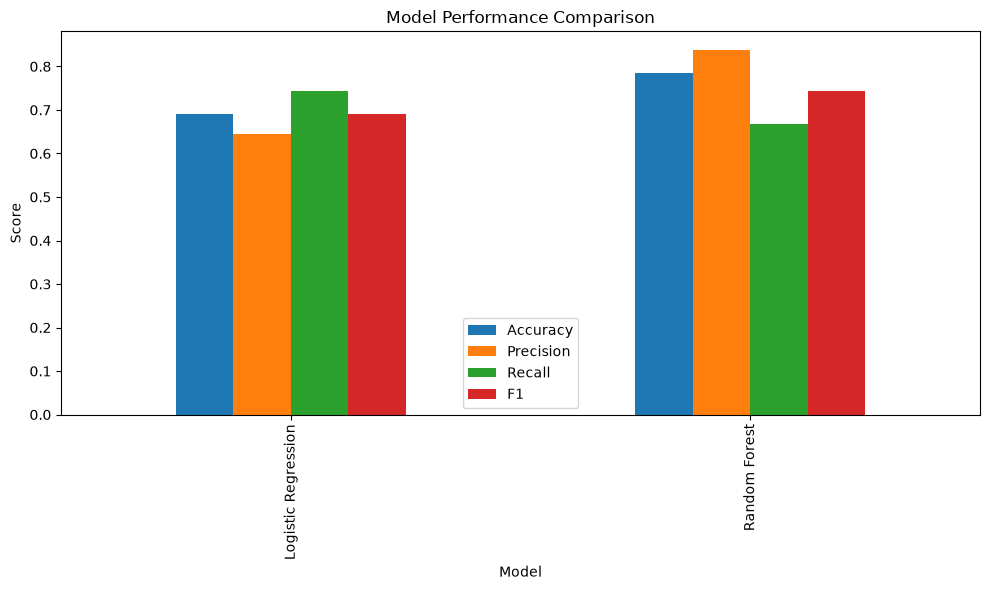

In [181]:
comparison_plot = comparison.set_index(
    "Model"
)

comparison_plot.plot(
    kind="bar",
    figsize=(10,6)
)

plt.title(
    "Model Performance Comparison"
)

plt.ylabel(
    "Score"
)

plt.tight_layout()

plt.savefig(
    "../results/figure/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## RF Feature Importance

In [182]:
importance_df = pd.DataFrame({

    "Feature":
        X.columns,

    "Importance":
        rf.feature_importances_

})

importance_df = (
    importance_df
    .sort_values(
        "Importance",
        ascending=False
    )
)

importance_df.head(15)

,Feature,Importance
0,price,0.271177
1,rating,0.143825
2,number_of_reviews,0.120456
95,variety_Unidentified,0.054523
116,location_Kab. Bekasi,0.040127
114,location_Kab. Bandung Barat,0.025950
20,variety_Compacta,0.022044
120,location_Kab. Gunung Kidul,0.020482
123,location_Kab. Kapuas Hulu,0.017132
117,location_Kab. Bogor,0.013077


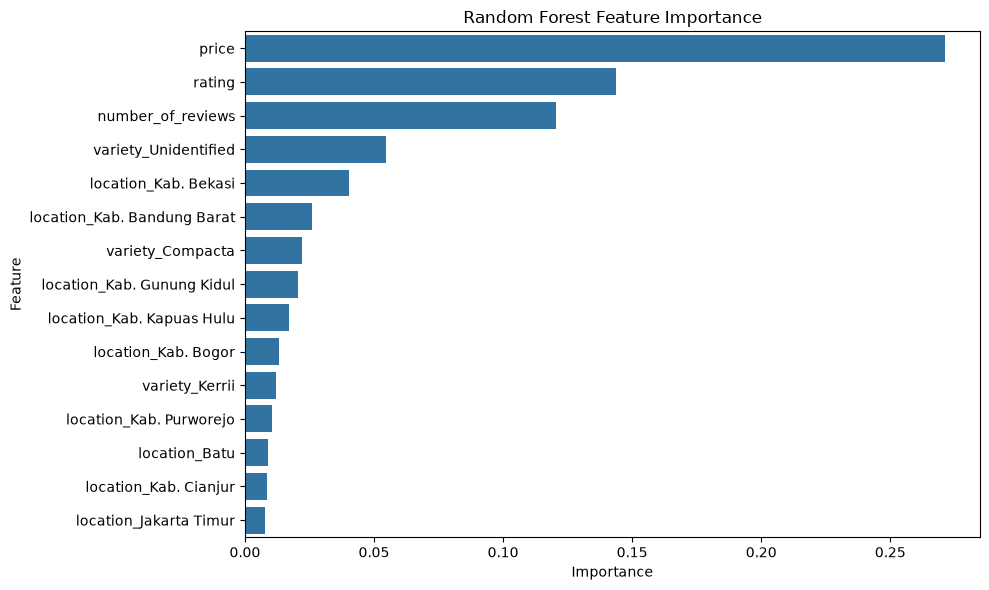

In [183]:
plt.figure(figsize=(10,6))

sns.barplot(

    data=importance_df.head(15),

    x="Importance",

    y="Feature"
)

plt.title(
    "Random Forest Feature Importance"
)

plt.tight_layout()

plt.savefig(
    "../results/figure/rf_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Shapley Additive Explanation (SHAP)

In [184]:
import shap

In [185]:
explainer = shap.TreeExplainer(
    rf
)

shap_values = explainer(
    X_test
)

### SHAP Summary Plot

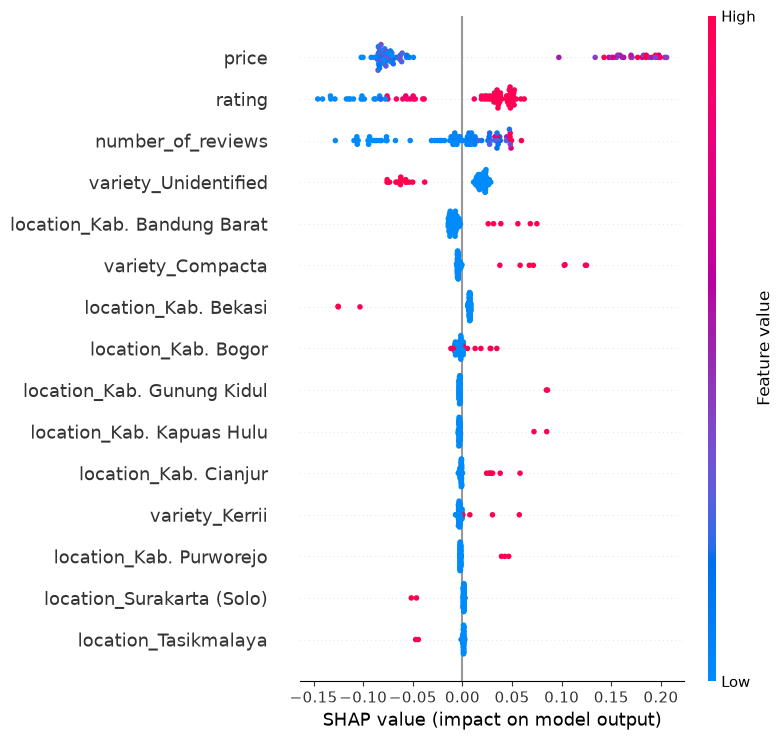

In [186]:
shap.summary_plot(
    shap_values[:,:,1],
    X_test,
    max_display=15,
    show=False
)

plt.tight_layout()

plt.savefig(
    "../results/figure/shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### SHAP Bar Plot

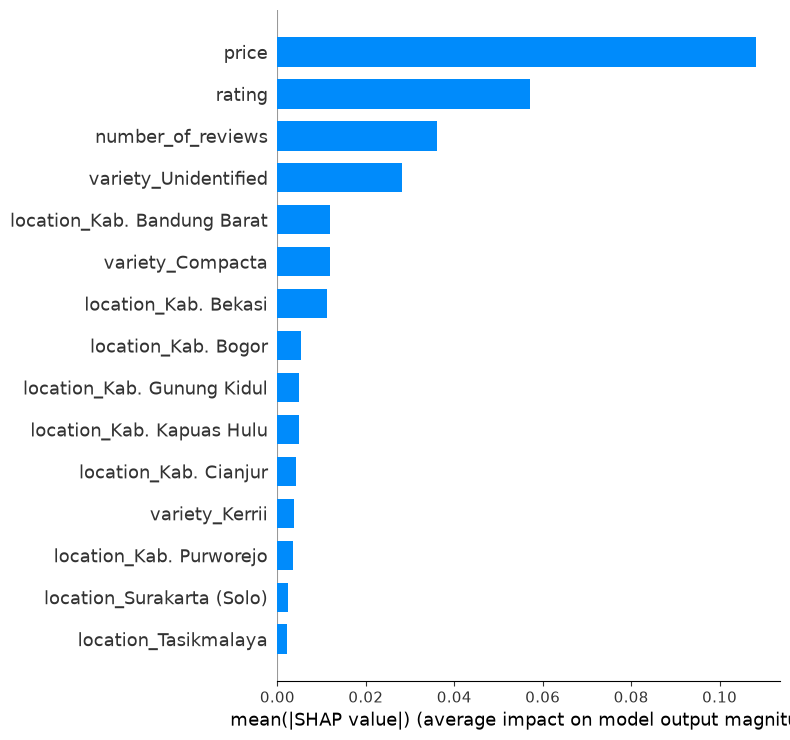

In [187]:
shap.summary_plot(

    shap_values[:,:,1],

    X_test,

    plot_type="bar",

    max_display=15

)

### Top Features

In [188]:
importance_df.head(10)

,Feature,Importance
0,price,0.271177
1,rating,0.143825
2,number_of_reviews,0.120456
95,variety_Unidentified,0.054523
116,location_Kab. Bekasi,0.040127
114,location_Kab. Bandung Barat,0.025950
20,variety_Compacta,0.022044
120,location_Kab. Gunung Kidul,0.020482
123,location_Kab. Kapuas Hulu,0.017132
117,location_Kab. Bogor,0.013077


Interpretation:

- Higher prices generally increase the likelihood of a listing being classified as high revenue.
- Listings with more reviews tend to have higher revenue potential.
- Product ratings contribute positively to classification performance.
- Certain Hoya varieties and seller locations exhibit stronger revenue potential than others.

In [189]:
# Export Results
comparison.to_csv(
    "../results/table/model_comparison.csv",
    index=False
)

importance_df.to_csv(
    "../results/table/rf_feature_importance.csv",
    index=False
)